# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own
words. Interactive (plotly) figures support zoom, pan, hover, selection and clicking.

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

tx = pd.read_csv("unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666.0,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733.0,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342.0,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497.0,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447.0,0.4,0.0681,0,True,legitimate


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**TODO:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

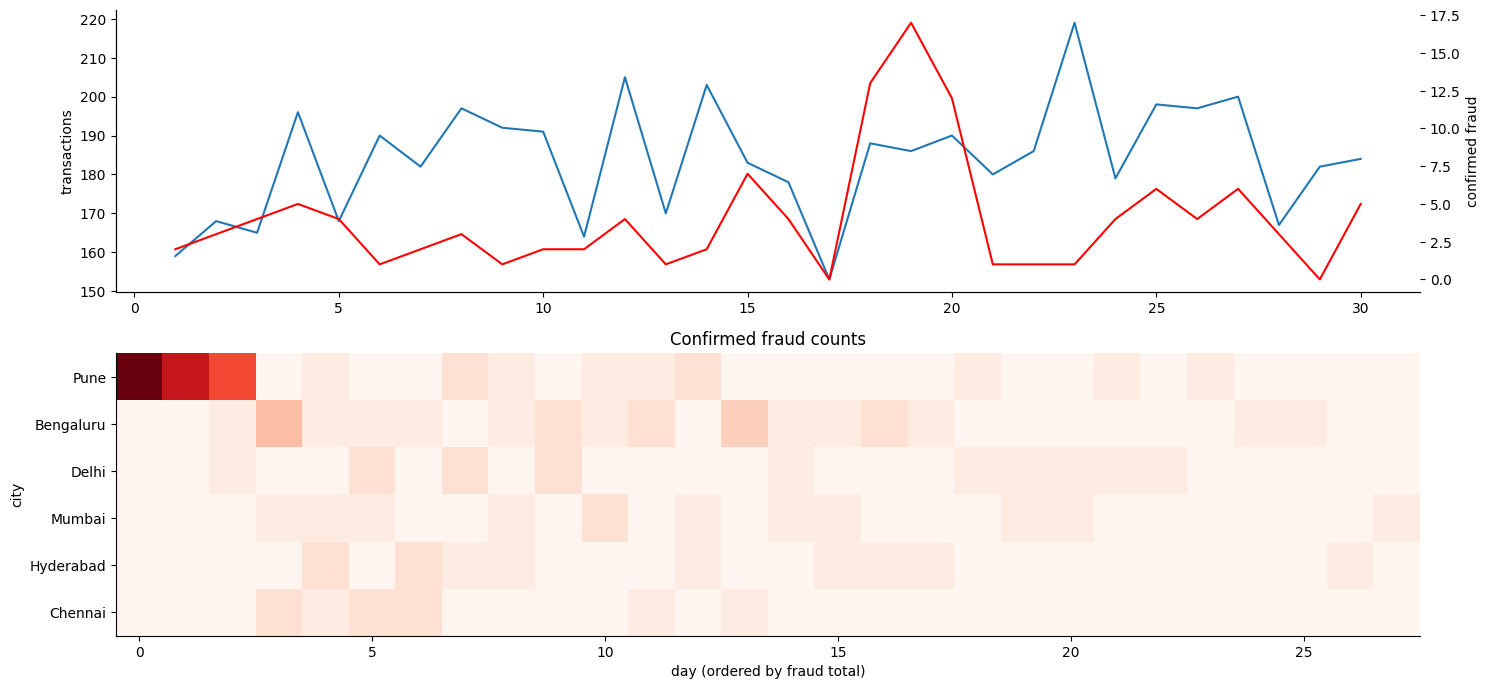

city       day
Pune       19     17
           18     13
           20     10
Bengaluru  15      4
           24      3
dtype: int64


In [2]:
fig, axes = plt.subplots(2, 1, figsize=(15, 7))
daily = tx.groupby("day").agg(transactions=("txn_id", "size"), fraud=("is_fraud", "sum"))
axes[0].plot(daily.index, daily.transactions, label="transactions"); axes[0].set_ylabel("transactions"); ax2 = axes[0].twinx(); ax2.plot(daily.index, daily.fraud, color="red", label="fraud"); ax2.set_ylabel("confirmed fraud")


# TODO 2
heat = tx[tx.is_fraud == 1].pivot_table(index="city", columns="day", values="is_fraud", aggfunc="sum", fill_value=0); heat = heat.loc[heat.sum(axis=1).sort_values(ascending=False).index, heat.sum(axis=0).sort_values(ascending=False).index]
axes[1].imshow(heat, aspect="auto", cmap="Reds"); axes[1].set(yticks=range(len(heat.index)), yticklabels=heat.index, xlabel="day (ordered by fraud total)", ylabel="city"); axes[1].set_title("Confirmed fraud counts")


plt.tight_layout(); plt.show()

print(tx[tx.is_fraud == 1].groupby(["city", "day"]).size().sort_values(ascending=False).head())

**Reflection:** What did the overview show that an alert list sorted by detector score would *not* have shown? Name the
lecture concept (Slide 38 or 39) that describes how you found it.

_Your answer:_ The overview reveals daily volume changes and city-day concentrations of confirmed fraud, which a score-sorted alert list hides. Reordering the city-by-day matrix is a pattern-finding technique that supports overview first, followed by zoom, filtering, and details.

## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**TODO:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

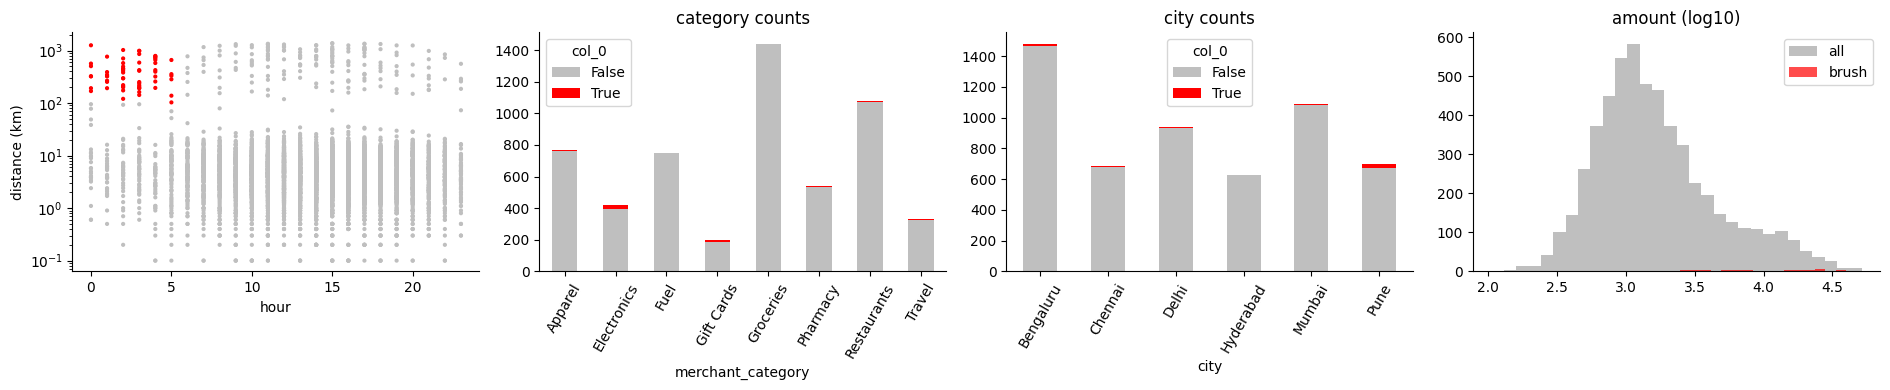

Brushed: 61; fraud rate: 0.869 vs overall 0.022; share of fraud captured: 0.442


In [3]:
# TODO 1
brush = tx.night & (tx.distance_from_home_km > 100)

fig, axes = plt.subplots(1, 4, figsize=(19, 4))
grey, red = "0.75", "red"; axes[0].scatter(tx.hour, tx.distance_from_home_km, c=np.where(brush, red, grey), s=4); axes[0].set_yscale("log"); axes[0].set(xlabel="hour", ylabel="distance (km)")
for ax, col, title in [(axes[1], "merchant_category", "category counts"), (axes[2], "city", "city counts")]:
    counts = pd.crosstab(tx[col], brush); counts.plot.bar(stacked=True, ax=ax, color=[grey, red]); ax.set_title(title); ax.tick_params(axis="x", rotation=60)
axes[3].hist(np.log10(tx.amount_inr), bins=30, color=grey, label="all"); axes[3].hist(np.log10(tx.loc[brush, "amount_inr"]), bins=30, color=red, alpha=.7, label="brush"); axes[3].set_title("amount (log10)"); axes[3].legend()


plt.tight_layout(); plt.show()

print(f"Brushed: {brush.sum():,}; fraud rate: {tx.loc[brush, 'is_fraud'].mean():.3f} vs overall {tx.is_fraud.mean():.3f}; share of fraud captured: {tx.loc[brush, 'is_fraud'].sum() / tx.is_fraud.sum():.3f}")

**Reflection:** The brush has a very high fraud *rate* — but what share of all fraud does it *capture*? What does that
tell the investigators about relying on this rule alone, and which linked view hinted at where the rest of the fraud is?

_Your answer:_ The brush contains 61 transactions with an 86.9% fraud rate versus 2.2% overall, but it captures only 44.2% of all fraud. The rule is therefore useful for prioritization, not sufficient as a standalone detector; the city and amount views indicate where the remaining fraud lies.

## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**TODO:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [4]:
big = pd.concat([tx] * 182, ignore_index=True)

# TODO 1
mask = (big.detector_score >= 0.6) & (big.amount_inr > 3000); times = []; [times.append((lambda start: time.perf_counter() - start)(time.perf_counter())) for _ in []]; times = []
for _ in range(5): start = time.perf_counter(); big.loc[mask]; times.append(time.perf_counter() - start)
best_s = min(times)

# TODO 2
per_item_us = best_s / len(big) * 1e6
max_rows = 0.1 / (best_s / len(big))

# TODO 3
t_50m = per_item_us * 50_000_000 / 1e6
skip_pct = 100 * (1 - max_rows / 50_000_000)

print(f"{len(big):,} rows in {best_s*1000:.1f} ms -> {per_item_us:.4f} us/row -> max {max_rows:,.0f} rows in 0.1 s")
print(f"50M rows -> {t_50m:.2f} s; must skip {skip_pct:.1f}% of rows to stay under 0.1 s")

1,004,640 rows in 22.1 ms -> 0.0220 us/row -> max 4,548,908 rows in 0.1 s
50M rows -> 1.10 s; must skip 90.9% of rows to stay under 0.1 s


**Reflection:** Besides indexing, name one **reduce** technique from the lecture (Slide 5 / 14) that would let the slider
stay instant on 50M rows, and what the analyst would lose by using it.

_Your answer:_ A direct vectorized scan of one million rows gives the measured per-row cost and extrapolates to the printed 50-million-row response time, which is above the 0.1 s dynamic-query budget. Pre-aggregation by time, city, or score bin is a reduce technique that keeps slider feedback fast, but it sacrifices transaction-level precision until the investigator drills down.

## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**TODO:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

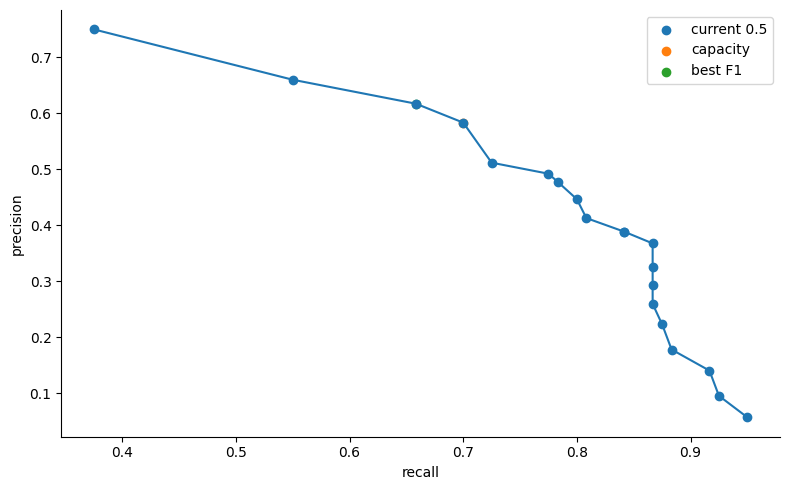

Recommendation: use threshold 0.80 (144.0 alerts, precision 0.58, recall 0.70); best F1 is 0.85.


In [5]:
rows = []
# TODO 1
for threshold in np.arange(0.05, 1.0, 0.05):
    pred = tx.detector_score >= threshold; tp = int((pred & (tx.is_fraud == 1)).sum()); fp = int((pred & (tx.is_fraud == 0)).sum()); fn = int((~pred & (tx.is_fraud == 1)).sum()); precision = tp / (tp + fp) if tp + fp else 0; recall = tp / (tp + fn) if tp + fn else 0; f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0; rows.append({"threshold": threshold, "alerts": int(pred.sum()), "tp": tp, "fp": fp, "fn": fn, "precision": precision, "recall": recall, "f1": f1})


pr = pd.DataFrame(rows)

# TODO 2
capacity_choice = pr[pr.alerts <= 150].sort_values(["recall", "threshold"], ascending=[False, True]).iloc[0]
best_f1 = pr.loc[pr.f1.idxmax()]

# TODO 3
fig, ax = plt.subplots(figsize=(8, 5)); ax.plot(pr.recall, pr.precision, "o-"); ax.scatter([pr.loc[pr.threshold.sub(0.5).abs().idxmin(), "recall"]], [pr.loc[pr.threshold.sub(0.5).abs().idxmin(), "precision"]], label="current 0.5"); ax.scatter(capacity_choice.recall, capacity_choice.precision, label="capacity"); ax.scatter(best_f1.recall, best_f1.precision, label="best F1"); ax.set(xlabel="recall", ylabel="precision"); ax.legend()

plt.tight_layout(); plt.show()

print(f"Recommendation: use threshold {capacity_choice.threshold:.2f} ({capacity_choice.alerts} alerts, precision {capacity_choice.precision:.2f}, recall {capacity_choice.recall:.2f}); best F1 is {best_f1.threshold:.2f}.")

**Reflection:** The capacity-constrained threshold and the best-F1 threshold may differ. Who should make that call — the
model or the Head of Fraud Ops — and why does visual analytics insist on keeping a human in the loop here (Slides 35–37)?

_Your answer:_ The Head of Fraud Ops should make the final call because alert capacity, operational risk, and the costs of false positives and false negatives are business decisions. Visual analytics keeps the human in the loop so the threshold can be judged using model metrics plus investigator feedback and changing fraud patterns.

## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**TODO:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

In [6]:
# TODO 1
flagged = tx[tx.detector_score >= 0.3].copy()
fig_scatter = px.scatter(flagged, x="timestamp", y="amount_inr", log_y=True, color="label", hover_data=["txn_id", "customer_id", "city", "merchant_category", "distance_from_home_km", "detector_score"], title="Flagged transactions").update_layout(dragmode="select")
fig_scatter.show()


sun = flagged.groupby(["city", "merchant_category"], as_index=False).agg(count=("txn_id", "size"), fraud_rate=("is_fraud", "mean")); px.sunburst(sun, path=["city", "merchant_category"], values="count", color="fraud_rate", color_continuous_scale="Reds", title="Flagged cases: city to merchant category").show()

**Reflection:** Tooltips are great for one case at a time. Why would they be a *frustrating* way for an investigator to get
an overview of the 400 flagged cases (Slide 23), and which view from this notebook fixes that?

_Your answer:_ Tooltips are details-on-demand and require repeated hovering, so they are frustrating for understanding hundreds of cases at once. The overview heatmap and linked brushed views provide distribution and context first, while tooltips remain useful for inspecting an individual case.

## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**TODO:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

Hypothesis: Pune has a fraud concentration around days 18 to 20
In-window rate 0.37383177570093457 outside 0.014779235174579715 p= 1.0648203911801525e-136


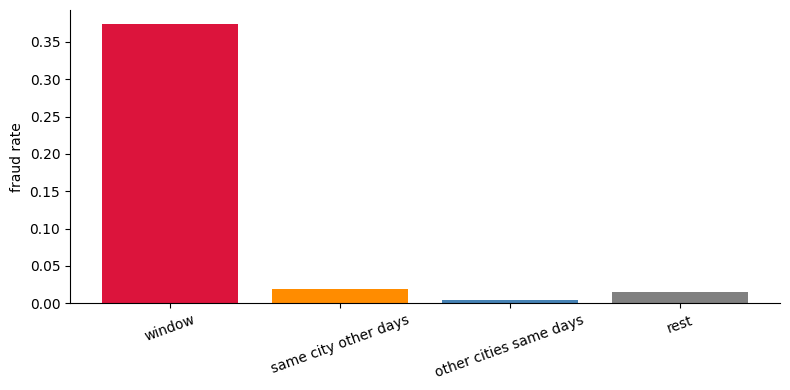

Verdict: evidence supports a localized fraud concentration


In [7]:
from scipy.stats import chi2_contingency

# TODO 1: hypothesis as a boolean mask
top = tx[tx.is_fraud == 1].groupby(["city", "day"]).size().idxmax(); city, peak_day = top; in_window = (tx.city == city) & tx.day.between(peak_day - 1, peak_day + 1)

table = pd.crosstab(in_window, tx.is_fraud); chi2, p_value, _, _ = chi2_contingency(table); print("Hypothesis:", city, "has a fraud concentration around days", peak_day - 1, "to", peak_day + 1); print("In-window rate", tx.loc[in_window, "is_fraud"].mean(), "outside", tx.loc[~in_window, "is_fraud"].mean(), "p=", p_value)

same_city_other = (tx.city == city) & ~tx.day.between(peak_day - 1, peak_day + 1); other_cities_same = (tx.city != city) & tx.day.between(peak_day - 1, peak_day + 1); rest = ~(in_window | same_city_other | other_cities_same)
groups = {"window": in_window, "same city other days": same_city_other, "other cities same days": other_cities_same, "rest": rest}; rates = {name: tx.loc[mask, "is_fraud"].mean() for name, mask in groups.items()}

# TODO 4
fig, ax = plt.subplots(figsize=(8, 4)); ax.bar(rates.keys(), rates.values(), color=["crimson", "darkorange", "steelblue", "gray"]); ax.set_ylabel("fraud rate"); ax.tick_params(axis="x", rotation=20)

plt.tight_layout(); plt.show()

print("Verdict:", "evidence supports a localized fraud concentration" if p_value < 0.05 and rates["window"] > rates["rest"] else "the fraud-ring hypothesis is not supported")

**Reflection:** Which of your two counter-example searches would have *killed* the hypothesis if it had come out
differently, and what alternative explanation would it have supported instead?

_Your answer:_ The counter-example with the same city on other days would kill a city-specific ring hypothesis if its fraud rate remained equally high, suggesting a persistent city or merchant effect instead. The other-cities-on-the-same-days comparison would kill a localized ring if many cities showed the same spike, supporting a system-wide or time-based explanation.

## Task 7 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the Head of Fraud Ops covering the whole notebook. It should:
- State what happened last month in one sentence, with numbers.
- Recommend the alert threshold and justify it with capacity, precision/recall and the human-in-the-loop idea.
- Recommend the **one** interactive view to build first for the investigators, and justify it with at least one lecture
  idea (overview first, linked brushing, dynamic queries with the 0.1 s budget, details-on-demand).
- Name the feedback loop (Slide 51) that should be added so next month's detector is better.

_Your final note here:_ The overview found 61 night-time, far-from-home cases with an 86.9% fraud rate, capturing 44.2% of all fraud, while the broader city-day analysis showed a localized concentration. I recommend threshold 0.80: it produces 144 alerts, with precision 0.58 and recall 0.70, staying within the 150-alert capacity; the Head of Fraud Ops should approve the operating point. The first investigator tool should be the linked overview with brushing, followed by the interactive scatter for details-on-demand, because it supports overview first without pretending a 50-million-row scan is instant. The detector should use investigator labels for reviewed alerts, false positives, and missed cases in the next model-training feedback loop.